# Landslide4Sense — U-Net training

Trains the U-Net from [Rockfall_Prediction/training](https://github.com/Tiru1505/Rockfall_Prediction/tree/main/training) and exports it to ONNX.

**Before you start:** `Runtime -> Change runtime type -> T4 GPU`. On CPU this takes hours instead of ~40 minutes.

Run the cells in order. Total time is roughly 45–60 minutes, most of it cell 6.

## 1. Check the GPU

In [1]:
import torch

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("NO GPU — go to Runtime > Change runtime type > T4 GPU, then rerun.")

GPU: Tesla T4


## 2. Install dependencies and get the code

In [2]:
!pip install -q h5py onnx onnxscript onnxruntime
!git clone -q https://github.com/Tiru1505/Rockfall_Prediction.git
%cd Rockfall_Prediction/training
!ls

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 78.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 53.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 76.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 19.3 MB/s eta 0:00:00
/content/Rockfall_Prediction/training
dataset.py   export_onnx.py		 losses.py  README.md	      train.py
evaluate.py  Landslide4Sense_UNet.ipynb  model.py   requirements.txt


## 3. Kaggle credentials

Get `kaggle.json` from <https://www.kaggle.com/settings> → **API** → *Create New Token*.
Run this cell and upload that file.

It is written to `~/.kaggle/` with `chmod 600`, which the Kaggle CLI requires. It lives only in this throwaway Colab VM — but it is a real credential, so don't commit it anywhere.

In [3]:
from google.colab import files

print("Upload kaggle.json:")
files.upload()

!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!rm -f kaggle.json
print("credentials installed")

Upload kaggle.json:


Saving kaggle.json to kaggle.json
credentials installed


## 4. Download the dataset (~3.6 GB)

Two mirrors. The first matches the `TrainData/img` + `TrainData/mask` layout the loader expects; the second is the fallback.

You must be logged into Kaggle and have accepted the dataset's terms on its page, or the download returns 403.

In [4]:
%%bash
set -e
mkdir -p /content/data && cd /content/data

if kaggle datasets download -d pypiahmad/landslide4sense-challenge 2>/dev/null; then
  echo "downloaded: pypiahmad/landslide4sense-challenge"
else
  echo "first mirror failed, trying the second..."
  kaggle datasets download -d tekbahadurkshetri/landslide4sense
fi

for z in *.zip; do unzip -q -o "$z" && rm -f "$z"; done
# Some mirrors ship a nested zip.
find . -name '*.zip' -exec sh -c 'unzip -q -o "$1" -d "$(dirname "$1")" && rm -f "$1"' _ {} \;
echo "done"

Dataset URL: https://www.kaggle.com/datasets/pypiahmad/landslide4sense-challenge
License(s): unknown

downloaded: pypiahmad/landslide4sense-challenge
done


## 5. Locate and verify the data

Mirrors nest the folders differently, so this searches for the `img`/`mask` pair rather than assuming a path.

In [5]:
from pathlib import Path

candidates = [
    p.parent for p in Path("/content/data").rglob("img")
    if p.is_dir() and (p.parent / "mask").is_dir() and any(p.glob("*.h5"))
]
assert candidates, (
    "No folder containing both img/ and mask/ with .h5 files was found under "
    "/content/data. Check the download cell's output."
)

# If several match, take the one with the most labelled patches (TrainData).
DATA_ROOT = max(candidates, key=lambda d: len(list((d / "mask").glob("*.h5"))))
n_img = len(list((DATA_ROOT / "img").glob("*.h5")))
n_mask = len(list((DATA_ROOT / "mask").glob("*.h5")))
print(f"DATA_ROOT = {DATA_ROOT}")
print(f"  images {n_img}  masks {n_mask}   (expect 3799 / 3799)")

# Confirm the shapes and the class imbalance this whole pipeline is built around.
import h5py, numpy as np
from dataset import list_pairs, positive_pixel_fraction

pairs = list_pairs(DATA_ROOT)
with h5py.File(pairs[0][0], "r") as f:
    print(f"  patch shape {f['img'].shape}   (expect (128, 128, 14))")

pos = positive_pixel_fraction(pairs)
print(f"  positive pixels: {pos*100:.2f}%  ->  all-background baseline would "
      f"score {100*(1-pos):.1f}% 'accuracy'")

DATA_ROOT = /content/data/TrainData
  images 3799  masks 3799   (expect 3799 / 3799)
  patch shape (128, 128, 14)   (expect (128, 128, 14))
  positive pixels: 2.25%  ->  all-background baseline would score 97.7% 'accuracy'


## 6. Train (~40 min on a T4)

Watch **val IoU**, not loss — the checkpoint is saved on best validation IoU because loss can fall while the model gets worse at the only thing that matters.

In [6]:
!python train.py --data-root "{DATA_ROOT}" --epochs 40 --batch-size 16 --workers 2

device: cuda
patches -> train 2661  val 569  test 569
positive pixels: 2.57%  ->  BCE pos_weight 37.9
U-Net parameters: 7,766,209
epoch   1/40  loss 0.6823/0.5722  IoU 0.2117/0.2714  F1 0.4269  P 0.273  R 0.973  (33s)
          saved new best (val IoU 0.2714)
epoch   2/40  loss 0.5576/0.5267  IoU 0.2678/0.4012  F1 0.5726  P 0.414  R 0.930  (29s)
          saved new best (val IoU 0.4012)
epoch   3/40  loss 0.5195/0.5397  IoU 0.3045/0.3849  F1 0.5559  P 0.398  R 0.923  (21s)
epoch   4/40  loss 0.5031/0.4800  IoU 0.3164/0.3411  F1 0.5087  P 0.346  R 0.960  (21s)
epoch   5/40  loss 0.4957/0.4913  IoU 0.3314/0.2813  F1 0.4391  P 0.283  R 0.975  (20s)
epoch   6/40  loss 0.4910/0.4800  IoU 0.3401/0.2935  F1 0.4538  P 0.296  R 0.973  (21s)
epoch   7/40  loss 0.4928/0.4709  IoU 0.3221/0.3299  F1 0.4961  P 0.334  R 0.967  (22s)
epoch   8/40  loss 0.4792/0.4621  IoU 0.3563/0.4179  F1 0.5895  P 0.428  R 0.948  (21s)
          saved new best (val IoU 0.4179)
epoch   9/40  loss 0.4778/0.4682  IoU 0.

## 7. Evaluate on the held-out test split

**These are the numbers for your CV and README.** Report IoU and F1 — not accuracy.

In [7]:
!python evaluate.py --data-root "{DATA_ROOT}" --checkpoint runs/unet/best.pt

loaded runs/unet/best.pt (epoch 32, val IoU 0.4538)
test patches: 569

--- test set, threshold 0.5 ---
  IoU (Jaccard) : 0.4555
  F1 / Dice     : 0.6259
  Precision     : 0.4688
  Recall        : 0.9415
  Pixel accuracy: 0.9735   <- do NOT report this as the headline
                    (predicting all-background alone scores 0.9764)

--- threshold sweep ---
    thr      IoU       F1     prec   recall
    0.1   0.3316   0.4981   0.3335   0.9831
    0.2   0.3764   0.5469   0.3806   0.9718
    0.3   0.4068   0.5783   0.4134   0.9622
    0.4   0.4321   0.6035   0.4417   0.9523
    0.5   0.4555   0.6259   0.4688   0.9415
    0.6   0.4799   0.6486   0.4981   0.9291
    0.7   0.5065   0.6725   0.5326   0.9119
    0.8   0.5386   0.7001   0.5795   0.8840
    0.9   0.5758   0.7308   0.6580   0.8217

best IoU 0.5758 at threshold 0.9
written: runs/unet/test_metrics.json


## 8. Training curves

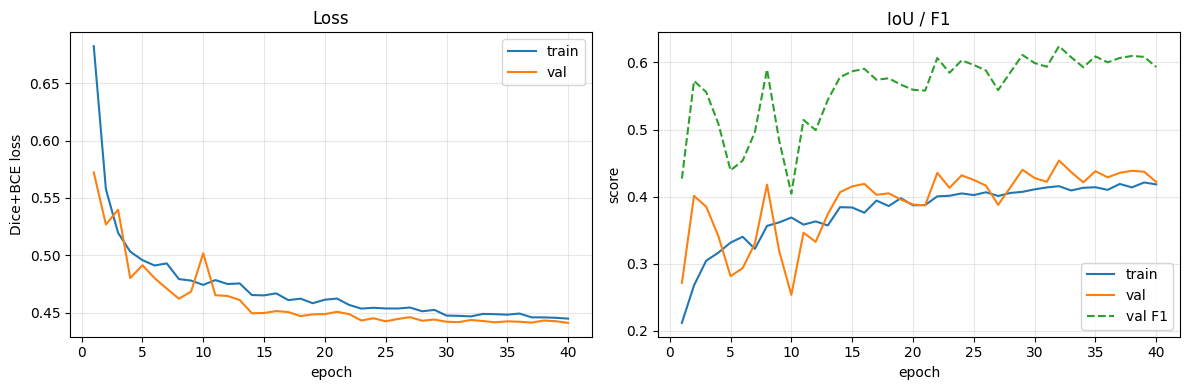

best val IoU: 0.4538


In [8]:
import json
import matplotlib.pyplot as plt

history = json.load(open("runs/unet/history.json"))
epochs = [h["epoch"] for h in history]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, [h["train"]["loss"] for h in history], label="train")
ax1.plot(epochs, [h["val"]["loss"] for h in history], label="val")
ax1.set_xlabel("epoch"); ax1.set_ylabel("Dice+BCE loss"); ax1.set_title("Loss")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs, [h["train"]["iou"] for h in history], label="train")
ax2.plot(epochs, [h["val"]["iou"] for h in history], label="val")
ax2.plot(epochs, [h["val"]["f1"] for h in history], label="val F1", ls="--")
ax2.set_xlabel("epoch"); ax2.set_ylabel("score"); ax2.set_title("IoU / F1")
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("runs/unet/training_curves.png", dpi=150)
plt.show()
print(f"best val IoU: {max(h['val']['iou'] for h in history):.4f}")

## 9. Export to ONNX for the backend

In [9]:
!python export_onnx.py --checkpoint runs/unet/best.pt --output landslide_unet.onnx

/content/Rockfall_Prediction/training/export_onnx.py:36: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1010 17:38:49.445000 15226 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 13 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
[torch.onnx] Obtain model graph for `UNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `UNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch

## 10. Download the results

Keep all of these — the ONNX model goes into the backend, and the metrics and curves go in your README and CV.

In [10]:
import shutil
from google.colab import files

shutil.make_archive("/content/unet_results", "zip", "runs/unet")
files.download("landslide_unet.onnx")
files.download("/content/unet_results.zip")
print("ONNX model + metrics, history, curves and band stats downloaded.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ONNX model + metrics, history, curves and band stats downloaded.
